# Team T085 · Section E · Project 26
Phase 1: Machine Learning

Role 3 supplies fitted-model diagnostics and row-aligned scores. The recorded experiment reuses a previously inspected test partition; it is not a fresh independent holdout. Final evaluation and robustness are separate role handoffs.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT=Path.cwd()
if ROOT.name=='notebooks': ROOT=ROOT.parent
assert (ROOT/'src').exists(), 'Start Jupyter in the project folder.'
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
TABLES=ROOT/'results/tables'
FIGURES=ROOT/'results/figures'
def table(name): return pd.read_csv(TABLES/name)
def figure(name): display(Image(filename=str(FIGURES/name)))


## GMM selection
Owner: Role 3. $p(x)=\sum_k\pi_k\mathcal N(x;\mu_k,\Sigma_k)$ and $s(x)=-\log p(x)$. EM computes soft responsibilities and weighted parameter updates. Training AIC/BIC share identical fitting observations and feature space. A staged optimizer search follows the 28 structural fits. Neither validation nor test labels choose the model.

,components,covariance,reg_covar,n_init,max_iter,seed,fit_rows,dimensions,aic,bic,converged,iterations,min_weight,min_cov_eigenvalue,max_cov_condition,ill_conditioned,seconds,stage,selected
0,1,diag,0.000010,2,300,26,170528,29,1.403430e+07,1.403489e+07,True,2,1.000000,1.000010e+00,1.000000e+00,False,0.153136,structure,False
1,2,diag,0.000010,2,300,26,170528,29,1.196709e+07,1.196826e+07,True,6,0.158889,1.094616e-01,9.187436e+00,False,0.637906,structure,False
2,4,diag,0.000010,2,300,26,170528,29,1.092261e+07,1.092497e+07,True,37,0.092096,2.997286e-03,3.532411e+02,False,1.921600,structure,False
3,8,diag,0.000010,2,300,26,170528,29,1.026996e+07,1.027469e+07,True,16,0.039745,6.266161e-03,1.711801e+02,False,1.847341,structure,False
4,12,diag,0.000010,2,300,26,170528,29,9.789948e+06,9.797051e+06,True,33,0.029024,1.950058e-03,4.457742e+02,False,5.553744,structure,False
5,16,diag,0.000010,2,300,26,170528,29,9.387039e+06,9.396513e+06,True,37,0.017503,1.596371e-03,5.368786e+02,False,4.752560,structure,False
6,20,diag,0.000010,2,300,26,170528,29,9.133816e+06,9.145661e+06,True,62,0.013563,1.558497e-03,9.136758e+02,False,7.912079,structure,False
7,1,full,0.000010,2,300,26,170528,29,1.374707e+07,1.375173e+07,True,2,1.000000,2.699350e-01,6.474971e+00,False,0.241261,structure,False
8,2,full,0.000010,2,300,26,170528,29,7.887389e+06,7.896722e+06,True,19,0.401171,3.637257e-05,8.795040e+04,False,2.273659,structure,False
9,4,full,0.000010,2,300,26,170528,29,-1.737211e+06,-1.718534e+06,True,18,0.113241,1.000000e-05,2.594086e+05,False,3.340887,structure,False


,components,covariance,reg_covar,n_init,max_iter,seed,fit_rows,dimensions,aic,bic,...,iterations,min_weight,min_cov_eigenvalue,max_cov_condition,ill_conditioned,error,warnings,seconds,stage,selected
28,20,full,0.000001,2,300,26,170528,29,-1.333943e+07,-1.324600e+07,...,63,0.001939,1.000000e-06,1.775911e+07,True,NaN,NaN,46.339986,optimizer,True


AIC winner:


,components,covariance,reg_covar,n_init,max_iter,seed,fit_rows,dimensions,aic,bic,...,iterations,min_weight,min_cov_eigenvalue,max_cov_condition,ill_conditioned,error,warnings,seconds,stage,selected
28,20,full,0.000001,2,300,26,170528,29,-1.333943e+07,-1.324600e+07,...,63,0.001939,1.000000e-06,1.775911e+07,True,NaN,NaN,46.339986,optimizer,True


Warnings and failures:


,components,covariance,reg_covar,n_init,max_iter,seed,fit_rows,dimensions,aic,bic,...,iterations,min_weight,min_cov_eigenvalue,max_cov_condition,ill_conditioned,error,warnings,seconds,stage,selected


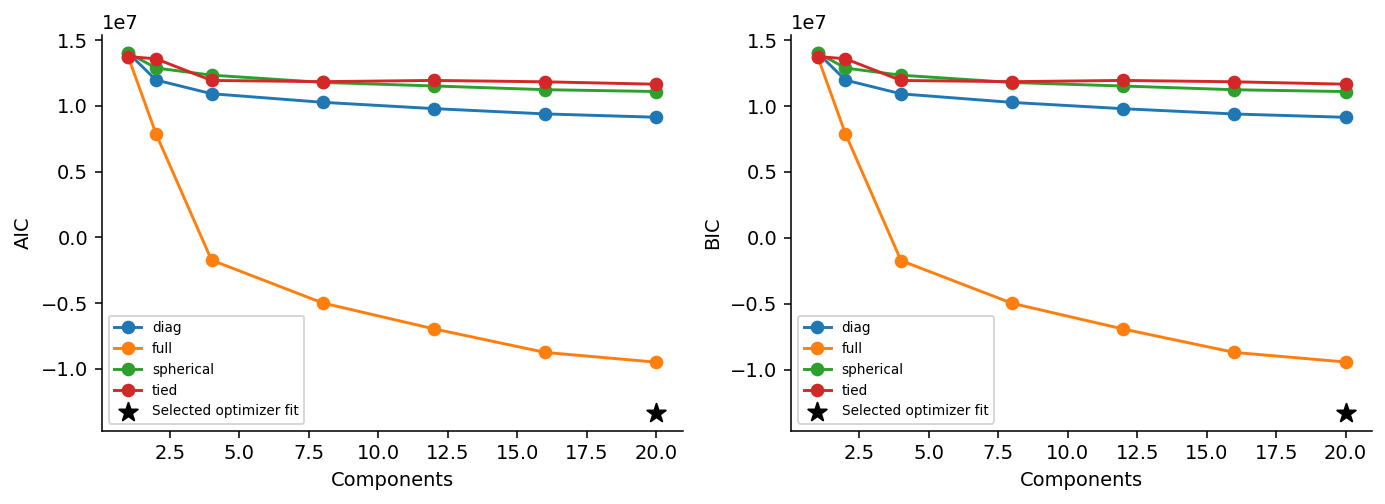

In [2]:
grid=table('gmm_grid.csv')
display(grid.drop(columns=['warnings','error']))
selected=grid[grid.selected]
display(selected)
print('AIC winner:');display(grid[grid.converged].sort_values('aic').head(1))
print('Warnings and failures:');display(grid[(grid.warnings.fillna('')!='') | (~grid.converged)])
figure('gmm_selection.png')

In [3]:
from src.data import load_raw, load_split_indices
import yaml
cfg=yaml.safe_load((ROOT/'configs/config.yaml').read_text())
path=ROOT/'data/raw/creditcard.csv'
raw=load_raw(path)
parts=load_split_indices(raw,ROOT/'data/processed/split_indices.npz',path,cfg['split_fractions'])
import joblib
from src.gmm_model import score
from src.features import preprocess
model_path=ROOT/'results/models/gmm.joblib'
if model_path.exists():
    model=joblib.load(model_path)
    pipeline=joblib.load(ROOT/'results/models/preprocessing.joblib')
    xv,_=preprocess(parts['validation'],pipeline=pipeline)
    computed=score(model,xv)
    saved=np.load(ROOT/'results/scores/gmm_validation.npz')
    np.testing.assert_allclose(computed,saved['score'])
    np.testing.assert_array_equal(parts['validation'].index,saved['source_row'])
    print('Validation scores and source IDs reproduced from saved model/pipeline.')
else:
    print('Set RETRAIN=True in the optional fit cell below, execute it, then rerun this verification cell.')

Validation scores and source IDs reproduced from saved model/pipeline.


In [4]:
# Optional full GMM reproduction; disabled while inspecting the recorded results.
RETRAIN=False
if RETRAIN:
    from src.features import prepare, preprocess
    from src.gmm_model import fit_grid, plot_selection
    from threadpoolctl import threadpool_limits
    xtrain, x, scaler=prepare(parts)
    with threadpool_limits(limits=2):
        model, grid=fit_grid(xtrain,cfg['gmm'],cfg['seed'])
        grid.to_csv(TABLES/'gmm_grid.csv',index=False)
        plot_selection(grid,FIGURES)
        _,pipeline=preprocess(parts['train'][parts['train'].Class==0])
        joblib.dump(model,ROOT/'results/models/gmm.joblib')
        joblib.dump(pipeline,ROOT/'results/models/preprocessing.joblib')
        joblib.dump(scaler,ROOT/'results/models/scaler.joblib')
        for split in ['validation','test']:
            ss=score(model,x[split])
            assert np.isfinite(ss).all()
            np.savez_compressed(ROOT/f'results/scores/gmm_{split}.npz',
                score=ss,source_row=parts[split].index.to_numpy())
    print('Regenerated GMM selection, fitted local objects and both score arrays.')


## Interpretation
Report convergence separately from conditioning and fraud ranking. The largest tested component count is only a bounded search endpoint. AIC/BIC do not select across different PCA dimensions or sample sizes. Continuous density and component membership are not fraud posterior probabilities.